# Visualization

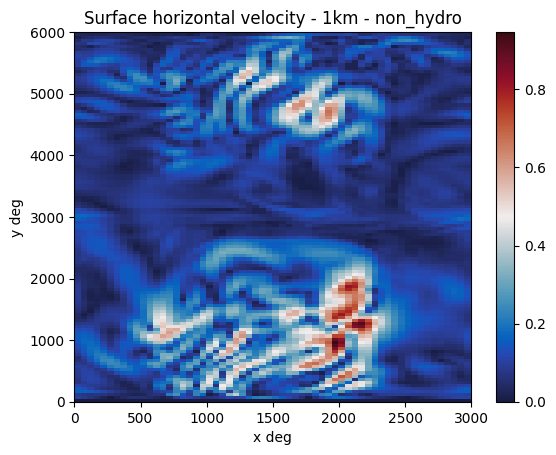

In [1]:
from MITgcmutils import diagnostics      # used to read in statistical diagnostics output
from MITgcmutils import mds
import numpy as np
import matplotlib.pyplot as plt
import cmocean
# Grid info

# path of the output files
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_50km_FK/verification/tutorial_reentrant_channel/'
path = 'run/'

XC = mds.rdmds(path_scratch + path_MITgcm + path + 'XC')
YC = mds.rdmds(path_scratch + path_MITgcm + path + 'YC')
U = mds.rdmds(path_scratch + path_MITgcm + path +'U', 2151360)
V = mds.rdmds(path_scratch + path_MITgcm + path +'V', 2151360)
u = np.sqrt(U**2 + V**2)
plt.pcolor(XC/1000, YC/1000, u[0,:,:], cmap=cmocean.cm.balance)
plt.title("Surface horizontal velocity - 1km - non_hydro")
plt.xlabel('x deg')
plt.ylabel('y deg') 
plt.colorbar()
plt.show()

# Vertical heat flux

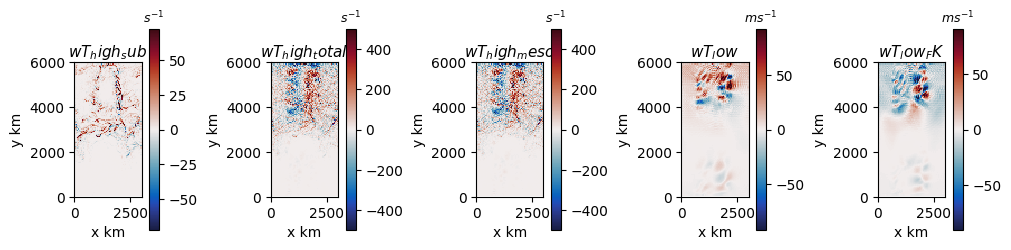

In [2]:
# High-resolution submesoscale heat flux
# ML_predicted submesoscale heat flux
# low-resolution submesoscale heat flux
# low resolution submesoscale heat flux with Fox Kemper parameterization

# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import wT_total
from src.utils import wT
from src.utils import make_grid
from src.utils import coarsen_UVWTS
from src.utils import mld_avg
import importlib
importlib.reload(wT_total)
importlib.reload(wT)
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_high = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
path_low_FK = 'MITgcm_50km_FK/verification/tutorial_reentrant_channel/run/'
path_low = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'

# grid_dir = path_scratch + path_MITgcm
ds_fine_high = read_mitgcm.read_mitgrid_staggered(path_scratch + path_high)
ds_coarse_high = build_coarse_grid.build_coarse_grid_staggered(ds_fine_high,box_j=10, box_i=10)

ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)
# 
# submesoscale heat flux
# high-resolution
box_j, box_i = 10, 10
W = read_mitgcm._ocean_var(path_scratch + path_high, "W", 14802912, ("k_l","j","i"))
T = read_mitgcm._ocean_var(path_scratch + path_high, "T", 14802912, ("k","j","i"))
W_c = coarsen_UVWTS.coarse_field("W", W, ds_fine_high, box_j, box_i)
T_c = coarsen_UVWTS.coarse_field("T", T, ds_fine_high, box_j, box_i)
diagMXL = mds.rdmds(path_scratch + path_high + 'Diags/' +'DiagMXL_2d', 14802912)
kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
ds_ocean_c = xr.Dataset(dict(T = T_c, W = W_c))
ds_ocean = xr.Dataset(dict(T = T, W = W))
wT_high_sub, wT_high_total, wT_high_meso = wT.submeso_vertical_heat_flux(ds_fine_high, ds_coarse_high, ds_ocean, ds_ocean_c, box_j = 10, box_i = 10, boundary_Z = "fill", to_wm2 = True)

kpphbl_coarse = coarsen_UVWTS.coarse_field("kpphbl", kpphbl, ds_fine_high, box_j, box_i)
wT_high_sub = mld_avg.mld_avg(wT_high_sub, kpphbl_coarse, ds_coarse_high)
wT_high_total = mld_avg.mld_avg(wT_high_total, kpphbl_coarse, ds_coarse_high)
wT_high_meso = mld_avg.mld_avg(wT_high_meso, kpphbl_coarse, ds_coarse_high)
#  low resolution with foxkemper
W = read_mitgcm._ocean_var(path_scratch + path_low_FK, "W", 2376000, ("k_l","j","i"))
T = read_mitgcm._ocean_var(path_scratch + path_low_FK, "T", 2376000, ("k","j","i"))
diagMXL = mds.rdmds(path_scratch + path_low_FK + 'Diags/' +'DiagMXL_2d', 2376000)
kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
ds_ocean = xr.Dataset(dict(T = T, W = W))
wT_low_FK = wT_total._vertical_heat_flux(ds_50,ds_ocean)
wT_low_FK = mld_avg.mld_avg(wT_low_FK, kpphbl, ds_50)
# low resolution 
W = read_mitgcm._ocean_var(path_scratch + path_low, "W", 2376000, ("k_l","j","i"))
T = read_mitgcm._ocean_var(path_scratch + path_low, "T", 2376000, ("k","j","i"))
diagMXL = mds.rdmds(path_scratch + path_low + 'Diags/' +'DiagMXL_2d', 2376000)
kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
ds_ocean = xr.Dataset(dict(T = T, W = W))
wT_low = wT_total._vertical_heat_flux(ds_50,ds_ocean)
wT_low = mld_avg.mld_avg(wT_low, kpphbl, ds_50)
    
# limits function
def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_50["XC"]
YC = ds_50["YC"]
fields = {
    r"$wT_{high-sub}$":         {"Z": wT_high_sub,  "units": r"$s^{-1}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$wT_{high-total}$":         {"Z": wT_high_total,  "units": r"$s^{-1}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$wT_{high_meso}$":         {"Z": wT_high_meso,  "units": r"$s^{-1}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$wT_{low}$":         {"Z": wT_low,  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$wT_{low_FK}$":         {"Z": wT_low_FK,  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
}     



# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None

# Plot: 2×5
fig, axes = plt.subplots(1,5, figsize=(10, 3), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./viz_last.png")
plt.show()